In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
from pathlib import Path
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
import nltk
from nltk.corpus import stopwords

# Download NLTK stopwords
nltk.download('stopwords')

# Automatically locate reviews_cleaned.csv regardless of current working directory
current_dir = Path.cwd()
candidate_paths = [
    current_dir / "data" / "processed" / "reviews_cleaned.csv",
    current_dir.parent / "data" / "processed" / "reviews_cleaned.csv",
    Path("a:/DS-Review-AI/data/processed/reviews_cleaned.csv"),
    Path("../data/processed/reviews_cleaned.csv").resolve()
]

csv_path = None
for path in candidate_paths:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("Could not locate 'reviews_cleaned.csv'. Please re-run the export cell in Notebook 1.")

# Load cleaned dataset
df = pd.read_csv(csv_path)
print(f"✅ Successfully loaded dataset from: {csv_path}")
print(f"Total rows: {len(df):,}")
df.head(2)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Ishaan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


✅ Successfully loaded dataset from: a:\DS-Review-AI\data\processed\reviews_cleaned.csv
Total rows: 393,890


,ProductId,Score,Summary,Text,full_text,datetime,review_year,review_month,helpfulness_ratio,summary_length,text_length,text_word_count,sentiment_label,cleaned_text
0,B001E4KFG0,5,Good Quality Dog Food,I have bought several of the Vitality canned d...,Good Quality Dog Food I have bought several of...,2011-04-27,2011,4,1.0,21,263,52,positive,good quality dog food bought several vitality ...
1,B00813GRG4,1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,Not as Advertised Product arrived labeled as J...,2012-09-07,2012,9,0.0,17,190,34,negative,not advertised product arrived labeled jumbo s...


In [2]:
# Custom stopword list: remove standard stopwords but KEEP negation words
standard_stopwords = set(stopwords.words('english'))
negation_words = {'not', 'no', 'nor', 'neither', 'never', 'cannot', 'dont', 'cant', 'wont'}
custom_stopwords = standard_stopwords - negation_words

def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Strip HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    
    # 2. Lowercase
    text = text.lower()
    
    # 3. Expand common contractions
    text = re.sub(r"can\'t", "cannot", text)
    text = re.sub(r"won\'t", "will not", text)
    text = re.sub(r"n\'t", " not", text)
    text = re.sub(r"\'re", " are", text)
    text = re.sub(r"\'s", " is", text)
    text = re.sub(r"\'d", " would", text)
    text = re.sub(r"\'ll", " will", text)
    text = re.sub(r"\'ve", " have", text)
    text = re.sub(r"\'m", " am", text)
    
    # 4. Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # 5. Remove extra whitespace and custom stopwords
    words = text.split()
    cleaned_words = [w for w in words if w not in custom_stopwords and len(w) > 1]
    
    return " ".join(cleaned_words)

print("Text cleaning function initialized.")

Text cleaning function initialized.


In [3]:
# Apply text cleaning pipeline
df['cleaned_text'] = df['full_text'].apply(clean_text)

# Inspect cleaned transformation
df[['full_text', 'cleaned_text']].head(3)

,full_text,cleaned_text
0,Good Quality Dog Food I have bought several of...,good quality dog food bought several vitality ...
1,Not as Advertised Product arrived labeled as J...,not advertised product arrived labeled jumbo s...
2,"""Delight"" says it all This is a confection tha...",delight says confection around centuries light...


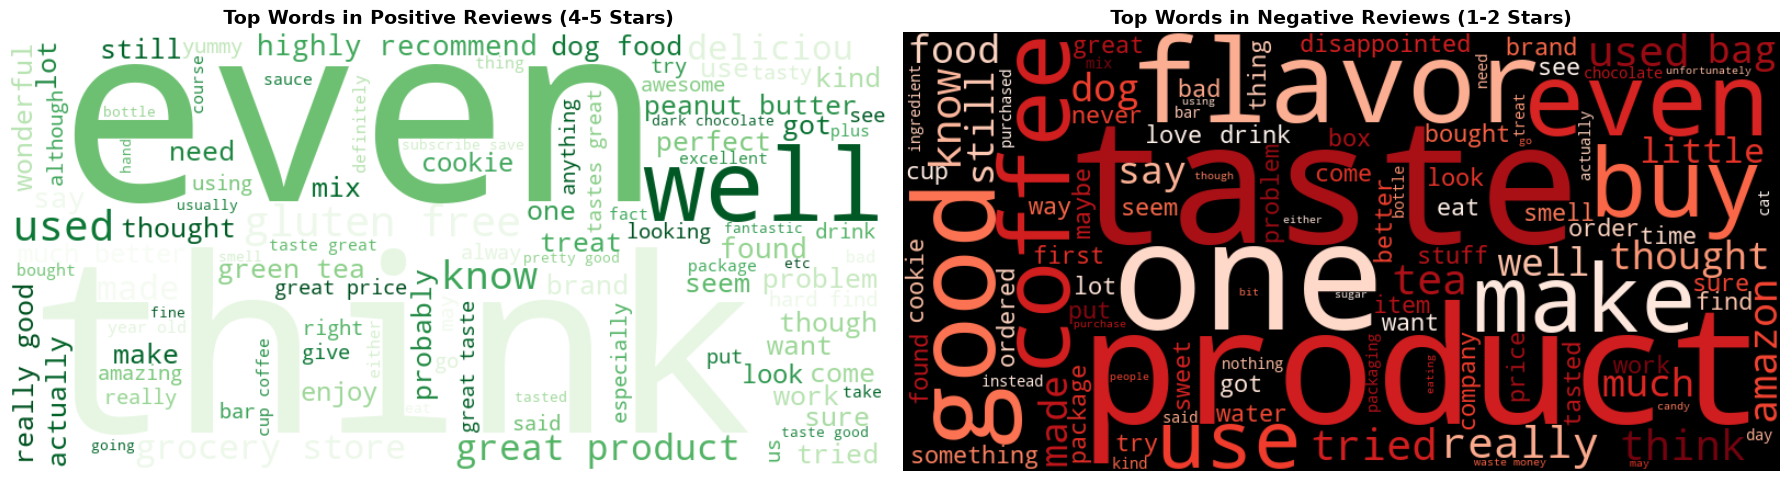

In [4]:
pos_text = " ".join(df[df['Score'] >= 4]['cleaned_text'].dropna())
neg_text = " ".join(df[df['Score'] <= 2]['cleaned_text'].dropna())

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Positive Word Cloud
wc_pos = WordCloud(width=800, height=400, background_color='white', max_words=100, colormap='Greens').generate(pos_text)
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].set_title('Top Words in Positive Reviews (4-5 Stars)', fontsize=14, fontweight='bold')
axes[0].axis('off')

# Negative Word Cloud
wc_neg = WordCloud(width=800, height=400, background_color='black', max_words=100, colormap='Reds').generate(neg_text)
axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].set_title('Top Words in Negative Reviews (1-2 Stars)', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()

C:\Users\Ishaan\AppData\Local\Temp\ipykernel_17280\3468585674.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pos_df, x='Count', y='Bigram', ax=axes[0], palette='Greens_r')
C:\Users\Ishaan\AppData\Local\Temp\ipykernel_17280\3468585674.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=neg_df, x='Count', y='Bigram', ax=axes[1], palette='Reds_r')


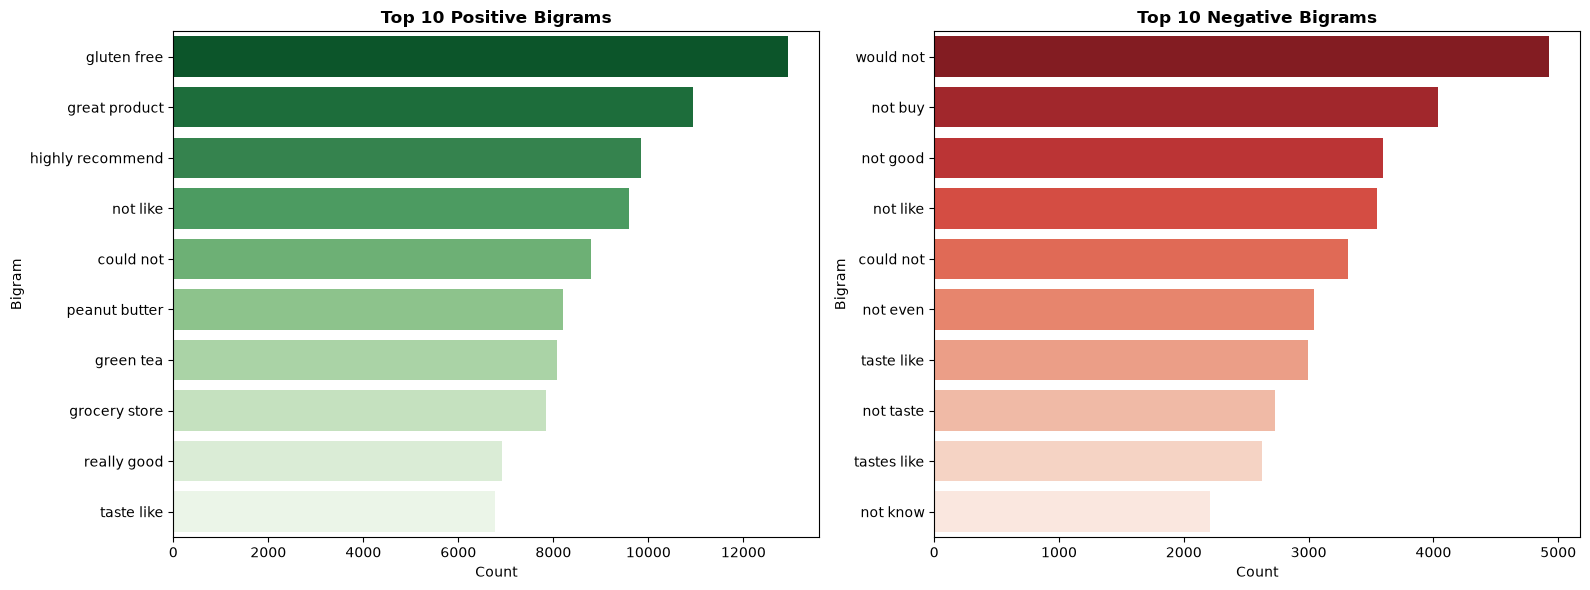

In [5]:
def get_top_bigrams(corpus, n=10):
    vec = CountVectorizer(ngram_range=(2, 2), min_df=5, max_features=5000).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0) 
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return pd.DataFrame(words_freq[:n], columns=['Bigram', 'Count'])

# Extract Bigrams for Positive and Negative reviews
pos_df = get_top_bigrams(df[df['Score'] >= 4]['cleaned_text'], n=10)
neg_df = get_top_bigrams(df[df['Score'] <= 2]['cleaned_text'], n=10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=pos_df, x='Count', y='Bigram', ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 10 Positive Bigrams', fontsize=12, fontweight='bold')

sns.barplot(data=neg_df, x='Count', y='Bigram', ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 10 Negative Bigrams', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

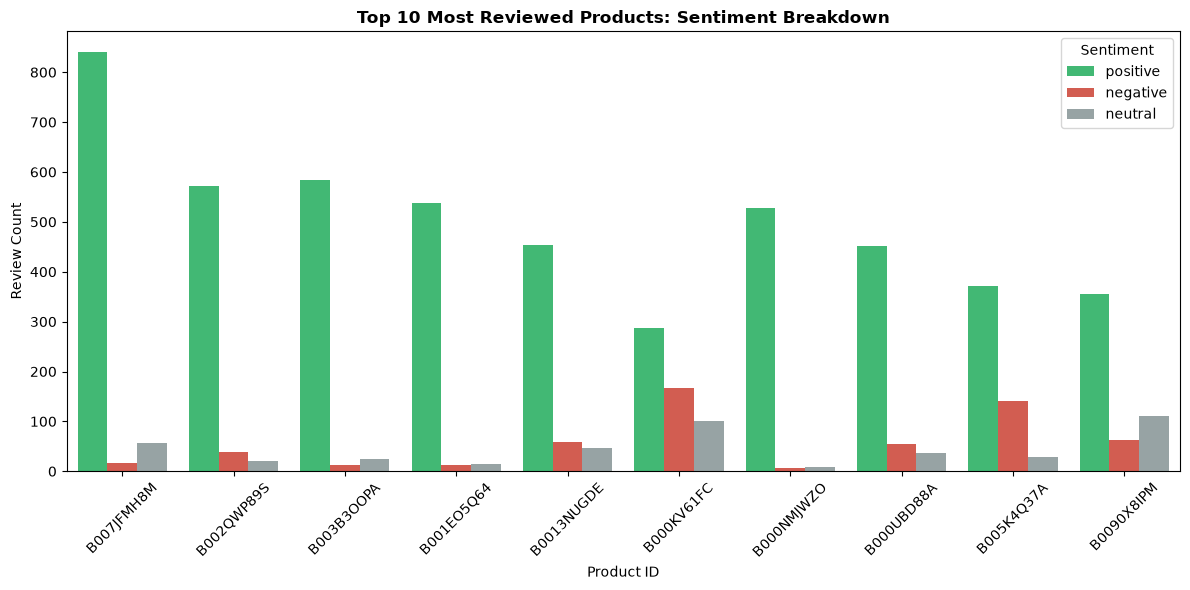

In [6]:
# Extract top 10 products by review volume
top_product_ids = df['ProductId'].value_counts().head(10).index
top_products_df = df[df['ProductId'].isin(top_product_ids)]

plt.figure(figsize=(12, 6))
sns.countplot(
    data=top_products_df, 
    x='ProductId', 
    hue='sentiment_label', 
    palette={'positive': '#2ecc71', 'negative': '#e74c3c', 'neutral': '#95a5a6'},
    order=top_product_ids
)
plt.title('Top 10 Most Reviewed Products: Sentiment Breakdown', fontsize=12, fontweight='bold')
plt.xlabel('Product ID')
plt.ylabel('Review Count')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

--- Helpfulness by Score (all reviews) ---
Score
1    0.412015
2    0.372368
3    0.356159
4    0.387983
5    0.436424
Name: helpfulness_ratio, dtype: float64

--- Helpfulness by Length Bucket (all reviews, unvoted=0) ---
length_bucket
short (<100)        0.402668
medium (100-300)    0.362167
long (300-600)      0.442308
very long (600+)    0.511560
Name: helpfulness_ratio, dtype: float64

--- % of Reviews with Zero Helpfulness Votes, by Length Bucket ---
length_bucket
short (<100)        51.40
medium (100-300)    58.86
long (300-600)      50.21
very long (600+)    41.99
Name: helpfulness_ratio, dtype: float64

Reviews with at least one vote: 186,626 of 393,890 (47.4%)

--- Helpfulness by Length Bucket (VOTED REVIEWS ONLY) ---
length_bucket
short (<100)        0.829
medium (100-300)    0.880
long (300-600)      0.888
very long (600+)    0.882
Name: helpfulness_ratio, dtype: float64

--- Helpfulness by Review Age (all vs voted-only) ---
                  all_reviews  voted_only
review_a

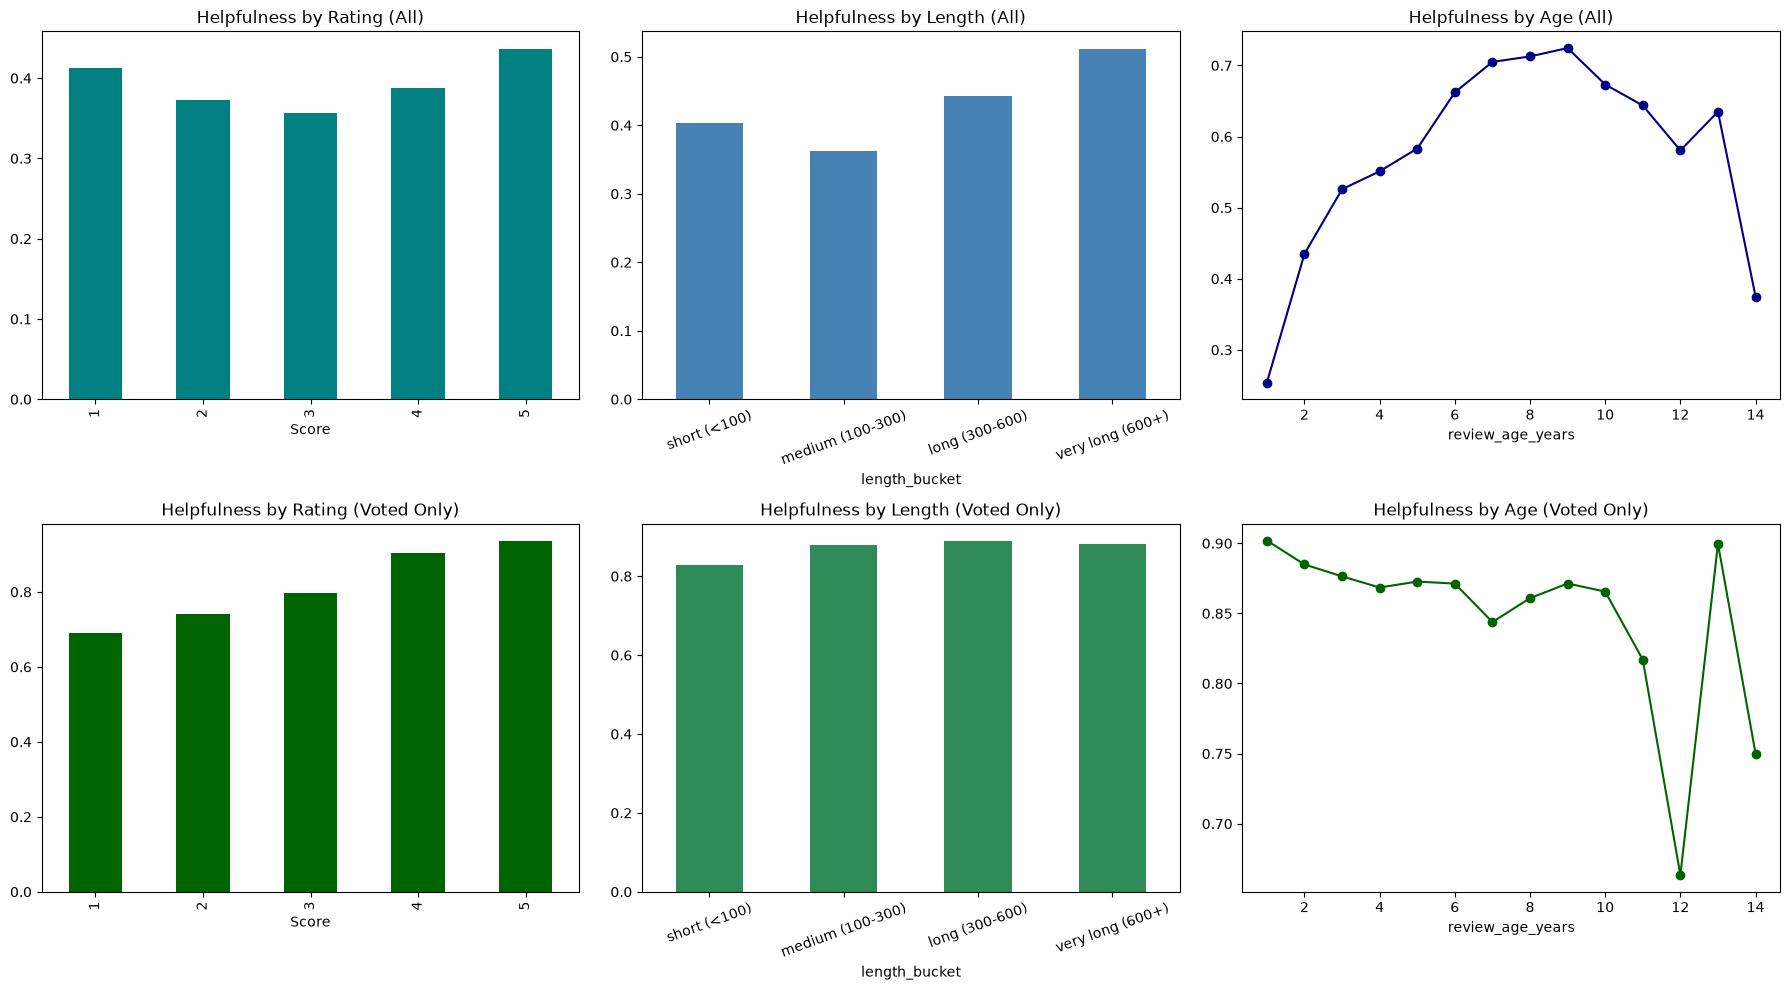

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('../reports', exist_ok=True)

# ==========================================
# 1. Helpfulness by rating (all reviews, as before)
# ==========================================
helpfulness_by_score = df.groupby('Score')['helpfulness_ratio'].mean()
print("--- Helpfulness by Score (all reviews) ---")
print(helpfulness_by_score)

# ==========================================
# 2. Helpfulness by review length
# ==========================================
df['length_bucket'] = pd.cut(
    df['text_length'],
    bins=[0, 100, 300, 600, 50000],
    labels=['short (<100)', 'medium (100-300)', 'long (300-600)', 'very long (600+)']
)
helpfulness_by_length_all = df.groupby('length_bucket', observed=False)['helpfulness_ratio'].mean()
print("\n--- Helpfulness by Length Bucket (all reviews, unvoted=0) ---")
print(helpfulness_by_length_all)

# ==========================================
# 3. Literature-backed check: separate "no votes" from "voted unhelpful"
# (HelpfulnessDenominator was dropped in Week 1, so we use helpfulness_ratio > 0
#  as a proxy for "received at least one vote" — documented limitation below)
# ==========================================
zero_vote_pct_by_length = df.groupby('length_bucket', observed=False)['helpfulness_ratio'].apply(
    lambda x: (x == 0).mean() * 100
)
print("\n--- % of Reviews with Zero Helpfulness Votes, by Length Bucket ---")
print(zero_vote_pct_by_length.round(2))

voted_only = df[df['helpfulness_ratio'] > 0]
print(f"\nReviews with at least one vote: {len(voted_only):,} of {len(df):,} "
      f"({len(voted_only)/len(df)*100:.1f}%)")
# Note: published research on this exact dataset drops unvoted reviews entirely
# for helpfulness analysis, reducing ~568K to ~298K (roughly half) — confirms
# this is not a fringe concern but standard practice for this dataset.

helpfulness_by_length_voted = voted_only.groupby('length_bucket', observed=False)['helpfulness_ratio'].mean()
print("\n--- Helpfulness by Length Bucket (VOTED REVIEWS ONLY) ---")
print(helpfulness_by_length_voted.round(3))

# ==========================================
# 4. Helpfulness by review age (dataset ends ~2012)
# ==========================================
df['review_age_years'] = 2013 - df['review_year']

# Re-create voted_only NOW that review_age_years exists on df
voted_only = df[df['helpfulness_ratio'] > 0]

helpfulness_by_age_all = df.groupby('review_age_years')['helpfulness_ratio'].mean()
helpfulness_by_age_voted = voted_only.groupby('review_age_years')['helpfulness_ratio'].mean()

print("\n--- Helpfulness by Review Age (all vs voted-only) ---")
print(pd.DataFrame({'all_reviews': helpfulness_by_age_all, 'voted_only': helpfulness_by_age_voted}))

# ==========================================
# Render & Export Visualizations — side-by-side "all" vs "voted only"
# ==========================================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

helpfulness_by_score.plot(kind='bar', ax=axes[0, 0], color='teal', title='Helpfulness by Rating (All)')
helpfulness_by_length_all.plot(kind='bar', ax=axes[0, 1], color='steelblue', title='Helpfulness by Length (All)')
axes[0, 1].tick_params(axis='x', rotation=20)
helpfulness_by_age_all.plot(kind='line', marker='o', ax=axes[0, 2], color='navy', title='Helpfulness by Age (All)')

voted_only.groupby('Score')['helpfulness_ratio'].mean().plot(
    kind='bar', ax=axes[1, 0], color='darkgreen', title='Helpfulness by Rating (Voted Only)')
helpfulness_by_length_voted.plot(kind='bar', ax=axes[1, 1], color='seagreen', title='Helpfulness by Length (Voted Only)')
axes[1, 1].tick_params(axis='x', rotation=20)
helpfulness_by_age_voted.plot(kind='line', marker='o', ax=axes[1, 2], color='darkgreen', title='Helpfulness by Age (Voted Only)')

plt.tight_layout()
plt.savefig('../reports/helpfulness_insight_comparison.png', dpi=300)
plt.show()

In [8]:
# ============================================================
# DAY 12: 16 PANDAS / SQL ANALYTICAL BUSINESS QUERIES
# ============================================================

print("--- Query 1: Overall Score Frequency Breakdown ---")
print(df['Score'].value_counts().sort_index())

print("\n--- Query 2: Target Sentiment Class Percentages ---")
print(df['sentiment_label'].value_counts(normalize=True).round(4) * 100)

print("\n--- Query 3: Top 10 Most Reviewed Products (by ASIN/ProductId) ---")
print(df['ProductId'].value_counts().head(10))

print("\n--- Query 4: Top 5 Products Receiving the Most 1-Star Reviews ---")
print(df[df['Score'] == 1]['ProductId'].value_counts().head(5))

print("\n--- Query 5: Average Review Length (Characters) by Star Rating ---")
print(df.groupby('Score')['text_length'].mean().round(2))

print("\n--- Query 6: Median Word Count per Sentiment Category ---")
print(df.groupby('sentiment_label')['text_word_count'].median())

print("\n--- Query 7: Total Review Submissions per Year ---")
print(df.groupby('review_year').size())

# FIX: relabeled — this pools every January/February/etc across all years,
# so it shows seasonality, not a historical year-over-year trend
print("\n--- Query 8: Review Volume by Month-of-Year (Seasonality, All Years Combined) ---")
print(df.groupby('review_month').size())

print("\n--- Query 9: Percentage of Reviews with ZERO Engagement (0 Votes) ---")
unvoted_pct = (df['helpfulness_ratio'] == 0.0).mean() * 100
print(f"Unvoted Reviews: {unvoted_pct:.2f}%")

print("\n--- Query 10: Top 5 Longest Positive Reviews (by Word Count) ---")
print(df[df['sentiment_label'] == 'positive'].nlargest(5, 'text_word_count')[['ProductId', 'Score', 'text_word_count']])

print("\n--- Query 11: Top 5 Longest Negative Reviews (by Word Count) ---")
print(df[df['sentiment_label'] == 'negative'].nlargest(5, 'text_word_count')[['ProductId', 'Score', 'text_word_count']])

# FIX: HelpfulnessDenominator was dropped in Week 1 — the old condition
# silently produced no output. Using voted_only (built in Day 11) as the proxy.
print("\n--- Query 12: Average Helpfulness Ratio for 1-Star Reviews (Voted Only) ---")
print(f"{voted_only[voted_only['Score'] == 1]['helpfulness_ratio'].mean():.4f}")
print("Note: exact vote-count filtering (>10 votes) isn't possible since")
print("HelpfulnessDenominator was dropped in Week 1 cleaning; using helpfulness_ratio > 0")
print("(voted_only) as a proxy for 'received at least one vote' instead.")

print("\n--- Query 13: Neutral (3-Star) Review Proportion by Year ---")
print((df[df['Score'] == 3].groupby('review_year').size() / df.groupby('review_year').size()).round(4) * 100)

print("\n--- Query 14: Correlation Matrix: Length, Word Count, and Helpfulness (All Reviews) ---")
print(df[['text_length', 'text_word_count', 'helpfulness_ratio']].corr().round(4))

# NEW: same correlation on voted-only reviews — cleaner signal, per Day 11 finding
print("\n--- Query 14b: Same Correlation, Voted Reviews Only (removes zero-vote noise) ---")
print(voted_only[['text_length', 'text_word_count', 'helpfulness_ratio']].corr().round(4))

print("\n--- Query 15: Products with at Least 100 Reviews and Highest Average Score ---")
product_stats = df.groupby('ProductId').agg(
    review_count=('Score', 'count'),
    mean_score=('Score', 'mean')
)
print(product_stats[product_stats['review_count'] >= 100].sort_values('mean_score', ascending=False).head(5))

--- Query 1: Overall Score Frequency Breakdown ---
Score
1     36302
2     20801
3     29768
4     56086
5    250933
Name: count, dtype: int64

--- Query 2: Target Sentiment Class Percentages ---
sentiment_label
positive    77.95
negative    14.50
neutral      7.56
Name: proportion, dtype: float64

--- Query 3: Top 10 Most Reviewed Products (by ASIN/ProductId) ---
ProductId
B007JFMH8M    912
B002QWP89S    630
B003B3OOPA    622
B001EO5Q64    566
B0013NUGDE    558
B000KV61FC    556
B000NMJWZO    542
B000UBD88A    542
B005K4Q37A    541
B0090X8IPM    530
Name: count, dtype: int64

--- Query 4: Top 5 Products Receiving the Most 1-Star Reviews ---
ProductId
B000X1Q1G8    134
B006N3I69A    105
B004SRH2B6    103
B005K4Q37A     96
B000KV61FC     89
Name: count, dtype: int64

--- Query 5: Average Review Length (Characters) by Star Rating ---
Score
1    451.83
2    492.96
3    524.29
4    500.58
5    401.43
Name: text_length, dtype: float64

--- Query 6: Median Word Count per Sentiment Category -

In [9]:
# Save updated dataset with cleaned_text column
df.to_csv(csv_path, index=False)
print(f"✅ Week 2 Notebook Complete! Saved {len(df):,} rows with 'cleaned_text' feature to '{csv_path}'.")


✅ Week 2 Notebook Complete! Saved 393,890 rows with 'cleaned_text' feature to 'a:\DS-Review-AI\data\processed\reviews_cleaned.csv'.
